# Malicious URL Classification — Initial Progress
**Dataset:** Phishing Attack Dataset (small, 520,285 samples)
**Focus this week:** Dataset validation, feature engineering & selection, baseline models
**Next week:** SVM, XGBoost, full 3-config comparison, tuning, final report

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from features import extract_all, LEXICAL_COLS, HOST_COLS, ALL_COLS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
import warnings; warnings.filterwarnings('ignore')
print('imports ok')

imports ok


## 1. Load & validate dataset

In [2]:
rows = []
with open('dephides/dataset/small_dataset/train.txt') as f:
    for line in f:
        line = line.rstrip('\n')
        if not line.strip():
            continue
        parts = line.split('\t')
        if len(parts) != 2:
            parts = line.split()
        if len(parts) != 2:
            continue
        rows.append(parts)
df = pd.DataFrame(rows, columns=['label', 'url'])
print('shape:', df.shape)
print(df['label'].value_counts())
print('duplicates:', df['url'].duplicated().sum())
df.head()

shape: (364198, 2)
label
legitimate    201736
phishing      162462
Name: count, dtype: int64
duplicates: 296


,label,url
0,legitimate,https://oregonstateparks.org/index.cfm?do=geti...
1,phishing,http://business.hsbc.com.camaract.mobi/system_...
2,phishing,http://facebook.com-source-page.com/help/conta...
3,legitimate,http://michaelnielsen.org/blog/lecture-course-...
4,phishing,http://messagerie-17fr.com/fr/91da56ae94f5f4ff...


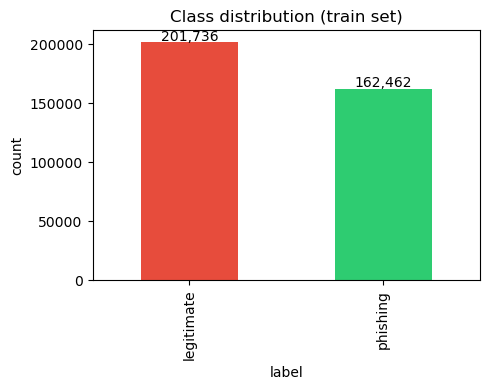

In [3]:
# label distribution plot
vc = df['label'].value_counts()
fig, ax = plt.subplots(figsize=(5,4))
vc.plot(kind='bar', ax=ax, color=['#e74c3c','#2ecc71'])
ax.set_title('Class distribution (train set)')
ax.set_ylabel('count')
for i,v in enumerate(vc.values):
    ax.text(i, v+1000, f'{v:,}', ha='center')
plt.tight_layout(); plt.show()

## 2. Feature engineering

In [4]:
# sample for speed during prototyping
sample = df.sample(n=20000, random_state=42).reset_index(drop=True)
feats = pd.DataFrame([extract_all(u) for u in sample['url']])
feats['label'] = sample['label'].values
print('feature matrix:', feats.shape)
feats.head()

feature matrix: (20000, 24)


,url_length,num_dots,num_slashes,num_digits,num_hyphens,num_underscores,num_at,num_question,num_equals,num_ampersand,...,query_length,domain_length,subdomain_count,has_subdomain,tld_length,registered_domain_length,hyphens_in_domain,digits_in_domain,domain_entropy,label
0,42,2,6,1,0,0,0,0,0,0,...,0,8,1,1,2,11,0,0,2.750000,legitimate
1,70,7,8,1,0,1,0,0,0,0,...,0,12,1,1,3,16,0,0,3.418296,phishing
2,83,1,5,24,3,0,0,0,0,0,...,0,23,0,0,3,27,3,0,3.501398,phishing
3,55,2,6,8,2,0,0,0,0,0,...,0,4,1,1,3,8,0,0,2.000000,legitimate
4,66,2,6,6,0,0,0,1,1,1,...,17,8,0,0,2,11,0,0,3.000000,phishing


In [5]:
# feature means by class
print(feats.groupby('label')[ALL_COLS].mean().T.round(3))

label                     legitimate  phishing
url_length                    72.854    86.441
num_dots                       2.236     3.694
num_slashes                    5.035     5.454
num_digits                     5.249    13.721
num_hyphens                    2.710     0.850
num_underscores                0.392     0.338
num_at                         0.001     0.019
num_question                   0.183     0.261
num_equals                     0.373     0.565
num_ampersand                  0.190     0.333
has_https                      0.662     0.023
has_ip                         0.001     0.045
suspicious_word_count          0.032     0.783
path_length                   40.394    35.767
query_length                   8.483    16.662
domain_length                  9.097    10.697
subdomain_count                0.719     1.344
has_subdomain                  0.719     0.593
tld_length                     3.120     2.989
registered_domain_length      13.217    14.049
hyphens_in_do

## 3. Feature selection (Random Forest importance)

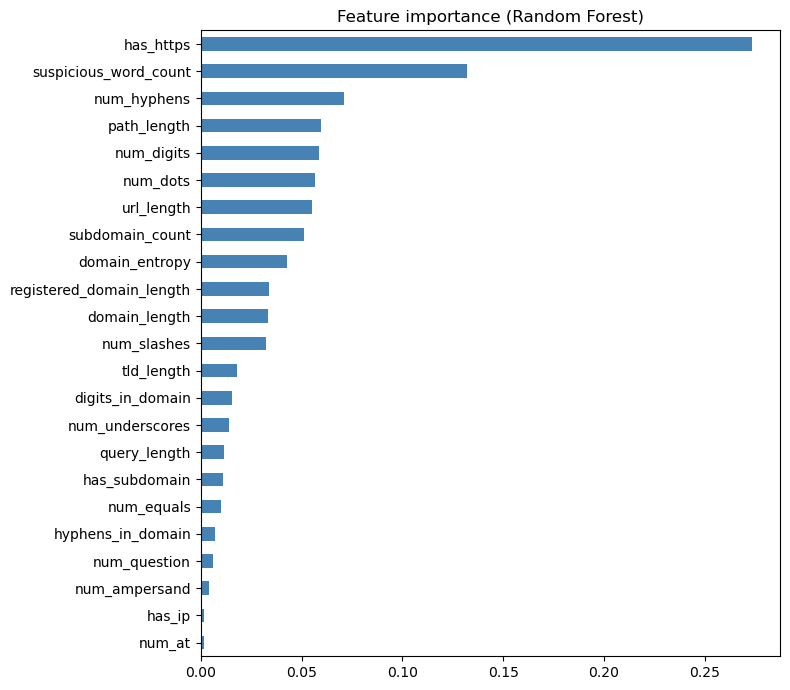

Top 10 features:
has_https                   0.273596
suspicious_word_count       0.132032
num_hyphens                 0.070981
path_length                 0.059580
num_digits                  0.058696
num_dots                    0.056847
url_length                  0.055016
subdomain_count             0.051075
domain_entropy              0.042715
registered_domain_length    0.034035
dtype: float64


In [6]:
X = feats[ALL_COLS]; y = (feats['label']=='phishing').astype(int)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X, y)
imp = pd.Series(rf.feature_importances_, index=ALL_COLS).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8,7))
imp.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Feature importance (Random Forest)')
plt.tight_layout(); plt.show()
print('Top 10 features:')
print(imp.sort_values(ascending=False).head(10))

## 4. Baseline models (combined features)

LogisticRegression: acc=0.9120 prec=0.9028 rec=0.8998 f1=0.9013


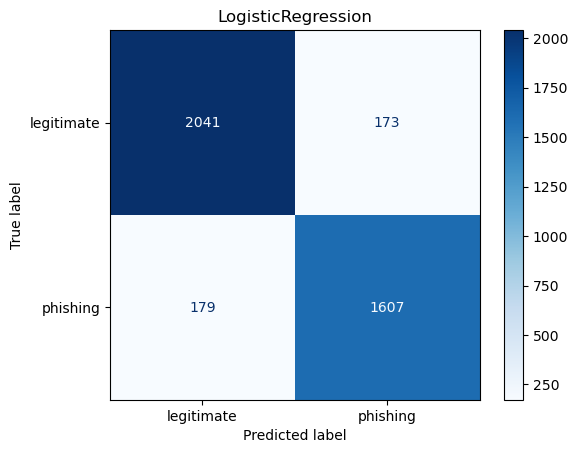

RandomForest: acc=0.9177 prec=0.9095 rec=0.9059 f1=0.9077


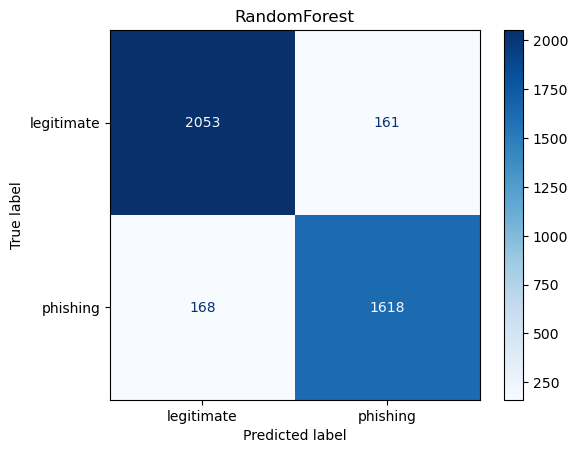

,model,accuracy,precision,recall,f1
0,LogisticRegression,0.91200,0.902809,0.899776,0.901290
1,RandomForest,0.91775,0.909500,0.905935,0.907714


In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
results = []
for name, model in [('LogisticRegression', LogisticRegression(max_iter=1000)),
                    ('RandomForest', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))]:
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    acc = accuracy_score(yte, pred)
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average='binary')
    results.append((name, acc, p, r, f1))
    print(f'{name}: acc={acc:.4f} prec={p:.4f} rec={r:.4f} f1={f1:.4f}')
    cm = confusion_matrix(yte, pred)
    ConfusionMatrixDisplay(cm, display_labels=['legitimate','phishing']).plot(cmap='Blues')
    plt.title(name); plt.show()
pd.DataFrame(results, columns=['model','accuracy','precision','recall','f1'])

## 5. Next-week plan

- Add SVM and XGBoost models.
- Compare **lexical-only**, **host-only**, **combined** feature configs.
- Hyperparameter tuning (GridSearch/RandomizedSearch).
- Evaluate on the official test split; produce final report + slides.
- Optional: scale to big_dataset if access granted.